Dataset Shape: (2000, 3)
Columns: Index(['BV (0-12)', 'Temperature (°C)', 'Status'], dtype='object')
[0]	train-logloss:0.59859	train-error:0.00000	test-logloss:0.59859	test-error:0.00000
[1]	train-logloss:0.52107	train-error:0.00000	test-logloss:0.52107	test-error:0.00000
[2]	train-logloss:0.45638	train-error:0.00000	test-logloss:0.45638	test-error:0.00000
[3]	train-logloss:0.40168	train-error:0.00000	test-logloss:0.40168	test-error:0.00000
[4]	train-logloss:0.35492	train-error:0.00000	test-logloss:0.35492	test-error:0.00000
[5]	train-logloss:0.31463	train-error:0.00000	test-logloss:0.31463	test-error:0.00000
[6]	train-logloss:0.27968	train-error:0.00000	test-logloss:0.27968	test-error:0.00000
[7]	train-logloss:0.24918	train-error:0.00000	test-logloss:0.24918	test-error:0.00000
[8]	train-logloss:0.22245	train-error:0.00000	test-logloss:0.22245	test-error:0.00000
[9]	train-logloss:0.19892	train-error:0.00000	test-logloss:0.19892	test-error:0.00000
[10]	train-logloss:0.17815	train-error:

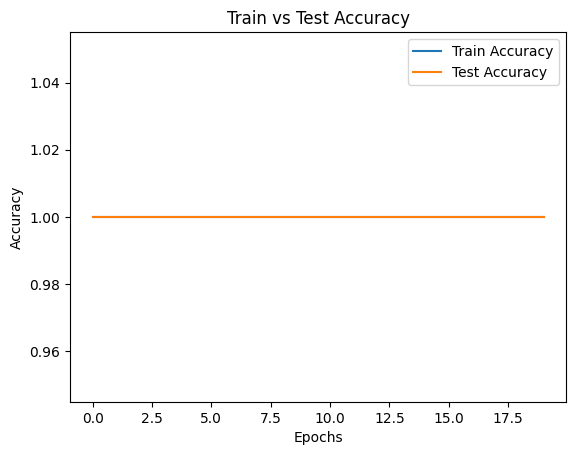

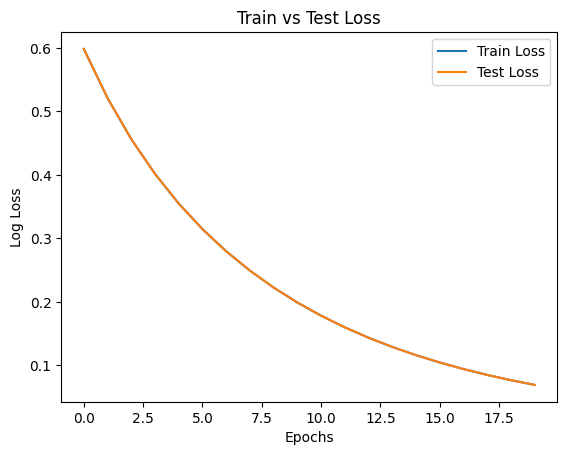


Model Saved Successfully as xgboost_temperature_model.json


In [1]:
# ===============================
# IMPORT LIBRARIES
# ===============================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

# ===============================
# LOAD DATASET
# ===============================
data = pd.read_csv("BV_Temperature_Range_Dataset_2000.csv")

print("Dataset Shape:", data.shape)
print("Columns:", data.columns)

# ===============================
# SPLIT FEATURES & LABEL
# (Assuming last column is label)
# ===============================
X = data.iloc[:, :-1]   # All columns except last
y = data.iloc[:, -1]    # Last column as label

# Encode labels if categorical
if y.dtype == 'object':
    encoder = LabelEncoder()
    y = encoder.fit_transform(y)

# ===============================
# TRAIN TEST SPLIT
# ===============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ===============================
# CONVERT TO DMatrix (XGBoost Format)
# ===============================
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

# ===============================
# MODEL PARAMETERS
# ===============================
params = {
    'objective': 'binary:logistic',   # Change to multi:softmax if multi-class
    'eval_metric': ['logloss', 'error'],
    'learning_rate': 0.1,
    'max_depth': 5,
    'seed': 42
}

# ===============================
# TRAIN MODEL (20 EPOCHS)
# ===============================
evals_result = {}

model = xgb.train(
    params,
    dtrain,
    num_boost_round=20,        # 20 epochs
    evals=[(dtrain, 'train'), (dtest, 'test')],
    evals_result=evals_result,
    verbose_eval=True
)

# ===============================
# PREDICTIONS
# ===============================
y_train_pred = model.predict(dtrain)
y_test_pred = model.predict(dtest)

# Convert probabilities to 0/1
y_train_pred = [1 if i > 0.5 else 0 for i in y_train_pred]
y_test_pred = [1 if i > 0.5 else 0 for i in y_test_pred]

# ===============================
# ACCURACY CALCULATION
# ===============================
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("\nTrain Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)

# ===============================
# PLOT ACCURACY GRAPH
# ===============================
epochs = len(evals_result['train']['error'])

train_accuracy_list = [1 - x for x in evals_result['train']['error']]
test_accuracy_list = [1 - x for x in evals_result['test']['error']]

plt.figure()
plt.plot(range(epochs), train_accuracy_list)
plt.plot(range(epochs), test_accuracy_list)
plt.title("Train vs Test Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(["Train Accuracy", "Test Accuracy"])
plt.show()

# ===============================
# PLOT LOSS GRAPH
# ===============================
plt.figure()
plt.plot(range(epochs), evals_result['train']['logloss'])
plt.plot(range(epochs), evals_result['test']['logloss'])
plt.title("Train vs Test Loss")
plt.xlabel("Epochs")
plt.ylabel("Log Loss")
plt.legend(["Train Loss", "Test Loss"])
plt.show()

# ===============================
# SAVE MODEL
# ===============================
model.save_model("xgboost_temperature_model.json")

print("\nModel Saved Successfully as xgboost_temperature_model.json")

Epoch 1: Train Acc=1.0000, Test Acc=1.0000
Epoch 2: Train Acc=1.0000, Test Acc=1.0000
Epoch 3: Train Acc=1.0000, Test Acc=1.0000
Epoch 4: Train Acc=1.0000, Test Acc=1.0000
Epoch 5: Train Acc=1.0000, Test Acc=1.0000
Epoch 6: Train Acc=1.0000, Test Acc=1.0000
Epoch 7: Train Acc=1.0000, Test Acc=1.0000
Epoch 8: Train Acc=1.0000, Test Acc=1.0000
Epoch 9: Train Acc=1.0000, Test Acc=1.0000
Epoch 10: Train Acc=1.0000, Test Acc=1.0000
Epoch 11: Train Acc=1.0000, Test Acc=1.0000
Epoch 12: Train Acc=1.0000, Test Acc=1.0000
Epoch 13: Train Acc=1.0000, Test Acc=1.0000
Epoch 14: Train Acc=1.0000, Test Acc=1.0000
Epoch 15: Train Acc=1.0000, Test Acc=1.0000
Epoch 16: Train Acc=1.0000, Test Acc=1.0000
Epoch 17: Train Acc=1.0000, Test Acc=1.0000
Epoch 18: Train Acc=1.0000, Test Acc=1.0000
Epoch 19: Train Acc=1.0000, Test Acc=1.0000
Epoch 20: Train Acc=1.0000, Test Acc=1.0000

Model Saved Successfully!


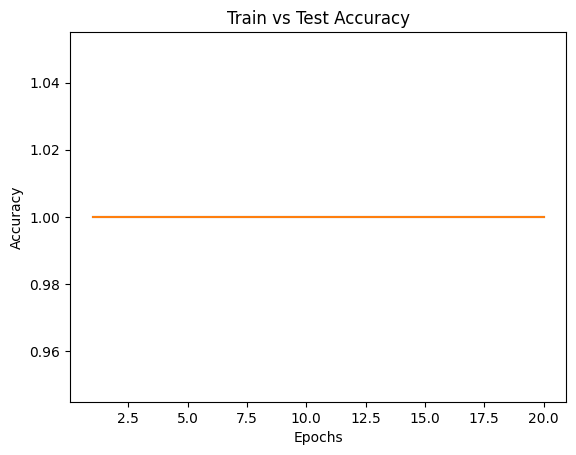

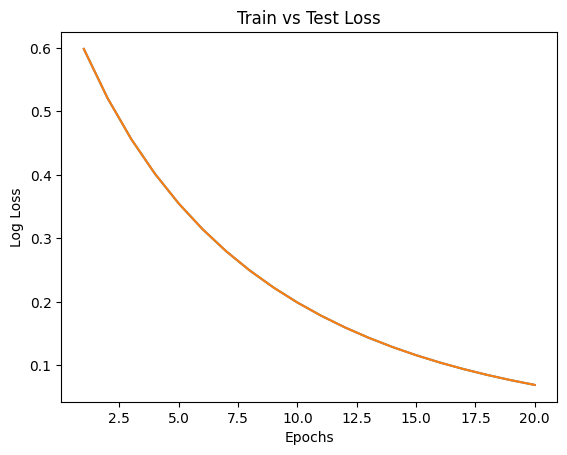

In [6]:
# ==============================
# XGBoost Vehicle Status Training
# ==============================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, log_loss
import xgboost as xgb
import joblib

# -----------------------------
# 1. Load Dataset
# -----------------------------
df = pd.read_csv("vehicle_status_dataset_2000.csv")

# -----------------------------
# 2. Separate Features & Label
# -----------------------------
X = df[["Battery_Voltage", "Temperature", "Gas_Flag"]]
y = df["Status"]

# Encode label (Normal=0, Danger=1)
le = LabelEncoder()
y = le.fit_transform(y)

# -----------------------------
# 3. Train Test Split
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Convert to XGBoost DMatrix
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

# -----------------------------
# 4. Model Parameters
# -----------------------------
params = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "max_depth": 4,
    "learning_rate": 0.1
}

epochs = 20

train_acc_list = []
test_acc_list = []
train_loss_list = []
test_loss_list = []

# -----------------------------
# 5. Training Loop (20 Epochs)
# -----------------------------
for i in range(1, epochs + 1):

    model = xgb.train(
        params,
        dtrain,
        num_boost_round=i
    )

    # Predictions
    train_prob = model.predict(dtrain)
    test_prob = model.predict(dtest)

    train_pred = (train_prob > 0.5).astype(int)
    test_pred = (test_prob > 0.5).astype(int)

    # Accuracy
    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    # Loss
    train_loss = log_loss(y_train, train_prob)
    test_loss = log_loss(y_test, test_prob)

    train_acc_list.append(train_acc)
    test_acc_list.append(test_acc)
    train_loss_list.append(train_loss)
    test_loss_list.append(test_loss)

    print(f"Epoch {i}: Train Acc={train_acc:.4f}, Test Acc={test_acc:.4f}")

# -----------------------------
# 6. Save Model
# -----------------------------
model.save_model("xgboost_vehicle_model.json")
joblib.dump(le, "label_encoder.pkl")

print("\nModel Saved Successfully!")

# -----------------------------
# 7. Accuracy Graph
# -----------------------------
plt.figure()
plt.plot(range(1, epochs + 1), train_acc_list)
plt.plot(range(1, epochs + 1), test_acc_list)
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Train vs Test Accuracy")
plt.show()

# -----------------------------
# 8. Loss Graph
# -----------------------------
plt.figure()
plt.plot(range(1, epochs + 1), train_loss_list)
plt.plot(range(1, epochs + 1), test_loss_list)
plt.xlabel("Epochs")
plt.ylabel("Log Loss")
plt.title("Train vs Test Loss")
plt.show()

[0]	train-logloss:0.60244	train-error:0.00000	test-logloss:0.60720	test-error:0.02500
[1]	train-logloss:0.52747	train-error:0.00000	test-logloss:0.53659	test-error:0.02500
[2]	train-logloss:0.46453	train-error:0.00000	test-logloss:0.47767	test-error:0.02500
[3]	train-logloss:0.41103	train-error:0.00000	test-logloss:0.42796	test-error:0.02500
[4]	train-logloss:0.36513	train-error:0.00000	test-logloss:0.38563	test-error:0.02500
[5]	train-logloss:0.32544	train-error:0.00000	test-logloss:0.34934	test-error:0.02500
[6]	train-logloss:0.29090	train-error:0.00000	test-logloss:0.31807	test-error:0.02500
[7]	train-logloss:0.26069	train-error:0.00000	test-logloss:0.29099	test-error:0.02500
[8]	train-logloss:0.23415	train-error:0.00000	test-logloss:0.26748	test-error:0.02500
[9]	train-logloss:0.21073	train-error:0.00000	test-logloss:0.24700	test-error:0.02500
[10]	train-logloss:0.19002	train-error:0.00000	test-logloss:0.22914	test-error:0.02500
[11]	train-logloss:0.17163	train-error:0.00000	test-l

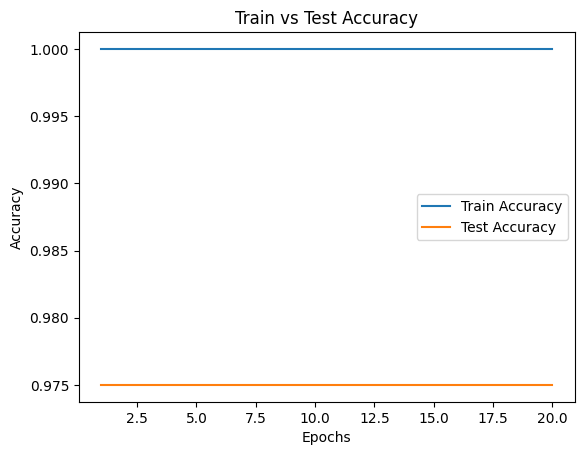

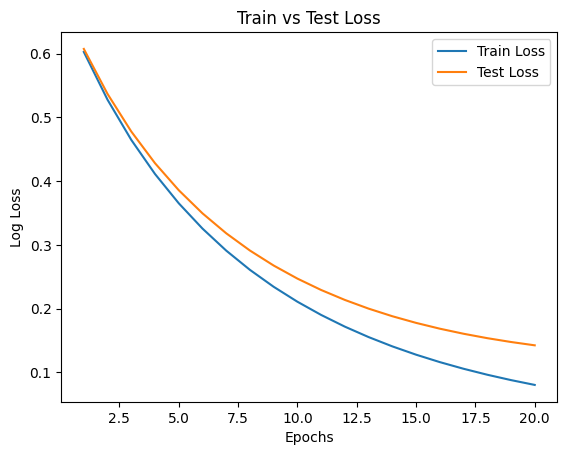

Model Saved Successfully!


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
import xgboost as xgb

# -----------------------------
# Load Dataset
# -----------------------------
data = pd.read_csv("battery_dataset.csv")

# Features and Label
X = data[["BV", "Temperature", "Gas_Flag", "Battery_Percentage"]]
y = data["Status"]

# Encode Label
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42
)

# Convert to DMatrix
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

# -----------------------------
# Model Parameters
# -----------------------------
params = {
    "objective": "binary:logistic",
    "eval_metric": ["logloss", "error"],
    "max_depth": 4,
    "learning_rate": 0.1
}

evals_result = {}

# -----------------------------
# Train Model (20 Epochs)
# -----------------------------
model = xgb.train(
    params,
    dtrain,
    num_boost_round=20,   # 20 epochs
    evals=[(dtrain, "train"), (dtest, "test")],
    evals_result=evals_result,
    verbose_eval=True
)

# -----------------------------
# Final Accuracy
# -----------------------------
y_train_pred = (model.predict(dtrain) > 0.5).astype(int)
y_test_pred = (model.predict(dtest) > 0.5).astype(int)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Final Train Accuracy:", train_accuracy)
print("Final Test Accuracy:", test_accuracy)

# -----------------------------
# Extract Metrics per Epoch
# -----------------------------
train_error = evals_result["train"]["error"]
test_error = evals_result["test"]["error"]

train_accuracy_epoch = [1 - e for e in train_error]
test_accuracy_epoch = [1 - e for e in test_error]

train_loss = evals_result["train"]["logloss"]
test_loss = evals_result["test"]["logloss"]

epochs = range(1, 21)

# -----------------------------
# Accuracy Graph
# -----------------------------
plt.figure()
plt.plot(epochs, train_accuracy_epoch)
plt.plot(epochs, test_accuracy_epoch)
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Train vs Test Accuracy")
plt.legend(["Train Accuracy", "Test Accuracy"])
plt.show()

# -----------------------------
# Loss Graph
# -----------------------------
plt.figure()
plt.plot(epochs, train_loss)
plt.plot(epochs, test_loss)
plt.xlabel("Epochs")
plt.ylabel("Log Loss")
plt.title("Train vs Test Loss")
plt.legend(["Train Loss", "Test Loss"])
plt.show()

# -----------------------------
# Save Model
# -----------------------------
model.save_model("xgboost_battery_model.json")
print("Model Saved Successfully!")